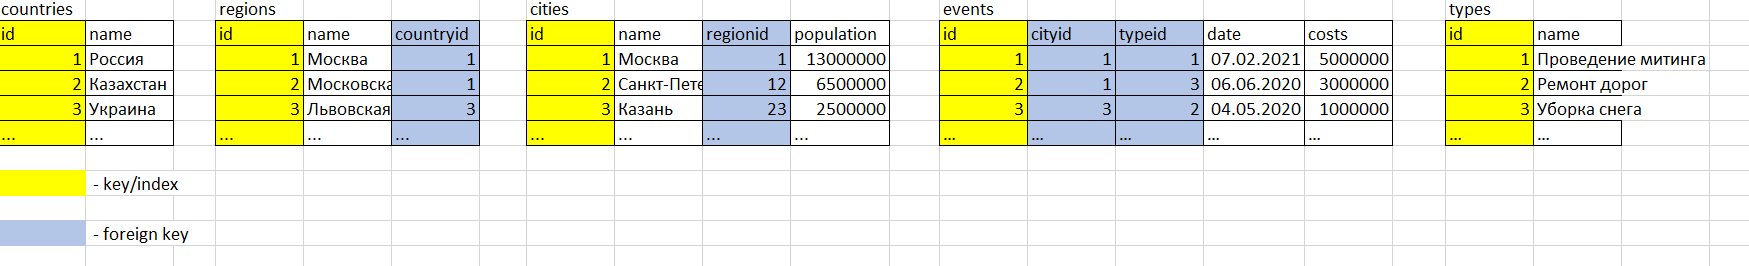

1. Название страны, в которой находится город "Казань".				

In [ ]:
SELECT name 
FROM countries c 
JOIN regions r 
    ON c.id=r.countryid     
WHERE r.name = 'Казань'		

2. Количество городов в московской области

In [ ]:
SELECT COUNT(name) AS count_name_cities
FROM cities c
JOIN regions r 
    ON c.redionid = r.id 
WHERE r.name = 'Московская область'

3. Количество уборок снега проведенных с начала декабря 2020 по конец февраля 2021.

In [ ]:
SELECT COUNT(name) AS count_name_types
FROM types t
JOIN events e 
    ON t.id = e.typeid
WHERE date >= '01.12.2020' AND date <= '28.02.2021'

4. Вывести городское население каждого региона.

In [ ]:
SELECT population, r.name AS region 
FROM cities c
JOIN regions r 
    ON c.redionid = r.id 
GROUP BY region


5. Посчитать кол-во уборок снега в Москве за последние 3 года

In [ ]:
SELECT 
    EXTRACT(YEAR FROM e.date) AS year,
    COUNT(*) AS snow_cleaning_count
FROM 
    events e
JOIN 
    cities c ON e.cityid = c.id
WHERE 
    c.name = 'Москва' 
    AND e.typeid = 3 
    AND e.date >= CURRENT_DATE - INTERVAL '3 years'

6. Посчитать средние траты на каждый тип события за последние 5 лет в Санкт-Петербурге

In [ ]:
SELECT AVG(costs) AS avg_costs,
       t.name 
FROM events e 
JOIN types t 
    ON e.typeid = t.id
JOIN cities c 
    ON e.cityid = c.id
WHERE c.name = 'Санкт-Петербург' AND e.date >= CURRENT_DATE - INTERVAL '5 years'

7. Посчитать среднее время между одинаковыми событиями для каждого города

In [ ]:
WITH event_times AS (
    SELECT 
        c.name AS city,
        e.typeid,
        e.date,
        LAG(e.date) OVER (PARTITION BY c.name, e.typeid ORDER BY e.date) AS prev_date
    FROM 
        events e
    JOIN 
        cities c ON e.cityid = c.id
),
time_diffs AS (
    SELECT 
        city,
        typeid,
        date - prev_date AS time_diff
    FROM 
        event_times
    WHERE 
        prev_date IS NOT NULL
)
SELECT 
    city,
    typeid,
    AVG(time_diff) AS avg_time_diff
FROM 
    time_diffs
GROUP BY 
    city, typeid
ORDER BY 
    city, typeid;

8. Посчитать среднюю стоимость трат по каждому типу события на 1 человека в год, для каждого региона

In [ ]:
WITH region_population AS (
    SELECT 
        r.name AS region,
        SUM(c.population) AS total_population
    FROM 
        regions r
    JOIN 
        cities c ON r.id = c.regionid
    GROUP BY 
        r.name
),
event_costs AS (
    SELECT 
        r.name AS region,
        t.name AS event_type,
        SUM(e.costs) AS total_costs
    FROM 
        events e
    JOIN 
        cities c ON e.cityid = c.id
    JOIN 
        regions r ON c.regionid = r.id
    JOIN 
        types t ON e.typeid = t.id
    GROUP BY 
        r.name, t.name
)
SELECT 
    ec.region,
    ec.event_type,
    ec.total_costs / rp.total_population AS avg_cost_per_person
FROM 
    event_costs ec
JOIN 
    region_population rp ON ec.region = rp.region
ORDER BY 
    ec.region, ec.event_type;